✓ Loaded image: signatures.jpg (2442x3621 px)


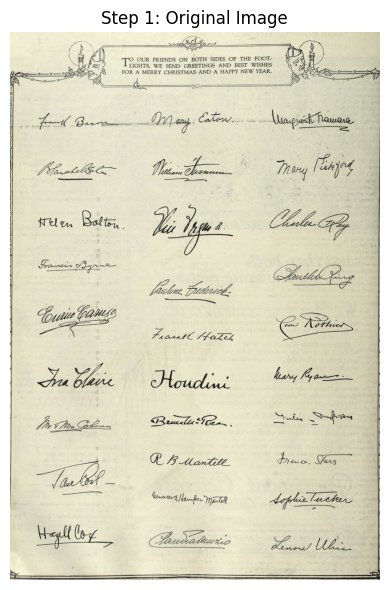

✓ Converted to grayscale and applied Gaussian blur (5x5)
✓ Applied Adaptive Threshold (blockSize=31, C=2)
  White pixels (ink): 1645552 | Black pixels (background): 7196930
✓ Applied minimal morphological cleaning (light open + close only)
✓ Cropped to bounding box (2442x3621 px) and re-thresholded for better pixel capture
✓ Applied Sharpening (minimal processing)
✓ Applied mask and ensured pure white background
  Masked white pixels: 1402368


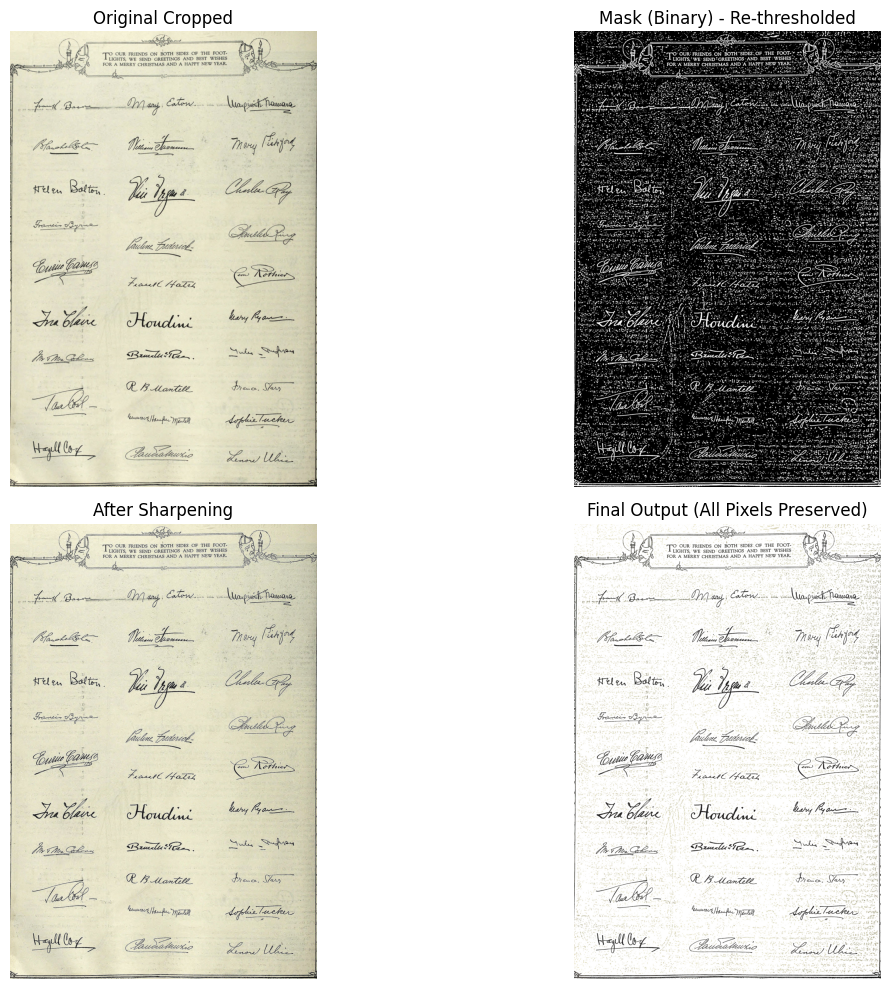


✓ SUCCESS: Saved to '/Users/aaronbaggot/Desktop/Assignment_2_Segmentation/clean_signature_enhanced.png'
  Final dimensions: 600x889 px
  Background: Pure white (no gray artifacts)
  All signature pixels preserved (blockSize=31, C=2)


In [13]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path


# SIGNATURE SEGMENTATION & ENHANCEMENT PIPELINE


# --- Step 1: Load Image ---
#input_path = 'boss.png'  
input_path = 'signatures.jpg'
img = cv2.imread(input_path)

if img is None:
    raise FileNotFoundError(f"Image not found at '{input_path}'")

print(f"✓ Loaded image: {input_path} ({img.shape[1]}x{img.shape[0]} px)")

# Display original
plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Step 1: Original Image")
plt.axis('off')
plt.tight_layout()
plt.show()

# --- Step 2: Grayscale & Blur ---
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

print(f"✓ Converted to grayscale and applied Gaussian blur (5x5)")

# --- Step 3: Adaptive Thresholding (Fine-tuned for pixel capture) ---
blockSize = 31  # Smaller for better discrimination
C = 2           # Back to 2 to capture missing pixels

binary = cv2.adaptiveThreshold(
    blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV, blockSize, C
)

print(f"✓ Applied Adaptive Threshold (blockSize={blockSize}, C={C})")
print(f"  White pixels (ink): {np.sum(binary == 255)} | Black pixels (background): {np.sum(binary == 0)}")

# --- Step 4: MINIMAL Morphological Cleaning ---
# Use only light cleaning to preserve fine details
kernel = np.ones((3, 3), np.uint8)
# Just a light open to remove tiny noise, then minimal close
clean_mask = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel, iterations=1)
# NO dilation/erosion - keep all signature pixels

print(f"✓ Applied minimal morphological cleaning (light open + close only)")

# --- Step 5: Crop to Bounding Box ---
coords = cv2.findNonZero(clean_mask)
if coords is None:
    raise ValueError("No signature detected! Try adjusting blockSize or C parameters.")

x, y, w, h = cv2.boundingRect(coords)
cropped_color = img[y:y+h, x:x+w].copy()
cropped_mask = clean_mask[y:y+h, x:x+w].copy()

# Re-run adaptive threshold on cropped region for better local adaptation
cropped_gray = cv2.cvtColor(cropped_color, cv2.COLOR_BGR2GRAY)
cropped_blurred = cv2.GaussianBlur(cropped_gray, (5, 5), 0)
cropped_binary = cv2.adaptiveThreshold(
    cropped_blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV, blockSize, C
)
cropped_mask = cv2.morphologyEx(cropped_binary, cv2.MORPH_OPEN, kernel, iterations=1)
cropped_mask = cv2.morphologyEx(cropped_mask, cv2.MORPH_CLOSE, kernel, iterations=1)

print(f"✓ Cropped to bounding box ({w}x{h} px) and re-thresholded for better pixel capture")

# --- Step 6: Simple Sharpening (NO denoising - preserve all pixels) ---
kernel_sharp = np.array([[-1,-1,-1],
                         [-1, 9,-1],
                         [-1,-1,-1]], dtype=np.float32)

sharpened = cv2.filter2D(cropped_color, -1, kernel_sharp)
# Clip to valid range [0, 255] to preserve all color channels properly
sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)

print(f"✓ Applied Sharpening (minimal processing)")

# --- Step 7: Apply Mask (Pure White Background) ---
mask_3ch = cv2.cvtColor(cropped_mask, cv2.COLOR_GRAY2BGR)

# Create output: where mask is white (255), use sharpened image, else use white (255)
# Use broadcasting to preserve all color channels
final_output = np.where(mask_3ch == 255, sharpened, 255).astype(np.uint8)

print(f"✓ Applied mask and ensured pure white background")
print(f"  Masked white pixels: {np.sum(np.all(cropped_mask == 255, axis=-1)) if len(cropped_mask.shape) == 3 else np.sum(cropped_mask == 255)}")

# --- Step 8: Display Comparison ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].imshow(cv2.cvtColor(cropped_color, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("Original Cropped")
axes[0, 0].axis('off')

axes[0, 1].imshow(cropped_mask, cmap='gray')
axes[0, 1].set_title("Mask (Binary) - Re-thresholded")
axes[0, 1].axis('off')

axes[1, 0].imshow(cv2.cvtColor(sharpened, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title("After Sharpening")
axes[1, 0].axis('off')

axes[1, 1].imshow(cv2.cvtColor(final_output, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title("Final Output (All Pixels Preserved)")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

# --- Step 9: Resize & Save ---
height, width = final_output.shape[:2]
target_width = 600
scale = target_width / width
resized = cv2.resize(final_output, (target_width, int(height * scale)), interpolation=cv2.INTER_CUBIC)

output_path = Path('clean_signature_enhanced.png')
cv2.imwrite(str(output_path), resized)

print(f"\n✓ SUCCESS: Saved to '{output_path.resolve()}'")
print(f"  Final dimensions: {resized.shape[1]}x{resized.shape[0]} px")
print(f"  Background: Pure white (no gray artifacts)")
print(f"  All signature pixels preserved (blockSize=31, C=2)")